# 02 · Normal-behaviour model, anomaly detection and evaluation

Reads the outputs of `python -m predmaint run --config configs/fuhrlander.yaml` (models are fitted there, not here),
so this notebook is a walk-through of the results. Steps:

1. **Normal-behaviour model (NBM):** LightGBM predicts each component temperature from load, recent load (1 h / 3 h),
   wind speed, generator speed and ambient temperature. Trained on healthy 2012 data only.
2. **Fleet screening:** each turbine's median residual in 2012 = its static offset vs. its sister turbines.
3. **Residuals → health score:** (measured − expected − static offset) / robust σ, averaged per day and component,
   minus the fleet's daily median (removes weather and fleet-wide drift), smoothed (EWMA, 3-day half-life).
4. **Alarm:** score above the training-period 99th percentile (median over turbines) for ≥ 2 days in a row.
5. **Evaluation (2013–2014):** days of warning before each fault event, and false-alarm episodes per turbine-year.

In [1]:
import json, pandas as pd
from IPython.display import Image, display, Markdown
from predmaint import pipeline
from predmaint.config import load_config
from predmaint.data import load_events
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
cfg = load_config("configs/fuhrlander.yaml")
events = load_events(cfg)
runs = {m: pipeline.load_run(cfg, m) for m in ["fleet", "self", "baseline"]}

## 1. How well does the model predict healthy temperatures?

In [2]:
acc = pd.concat({m: runs[m]["nbm_metrics"].set_index("signal")[["mae", "r2"]] for m in ["fleet", "self", "baseline"]}, axis=1)
acc.round(2)

fleet        self       baseline      
                                  mae    r2   mae    r2      mae    r2
signal                                                                
gearbox_temp                     1.41  0.92  1.30  0.94     5.68  0.00
gearbox_oil_temp                 1.58  0.75  1.56  0.78     3.42 -0.10
gearbox_bearing_151_temp         1.40  0.81  1.38  0.83     3.55 -0.04
gearbox_bearing_152_temp         1.36  0.90  1.28  0.92     4.89  0.00
gearbox_bearing_450_temp         1.63  0.71  1.58  0.76     3.22 -0.06
gearbox_bearing_451_temp         1.61  0.73  1.58  0.76     3.41 -0.16
gearbox_bearing_452_temp         1.81  0.36  1.81  0.37     2.59 -0.63
main_bearing_1_temp              2.09  0.71  1.98  0.73     3.90  0.13
main_bearing_2_temp              2.01  0.70  1.92  0.72     3.83  0.10
generator_winding_a_temp         3.83  0.93  3.64  0.94    14.62 -0.14
generator_winding_b_temp         3.88  0.93  3.70  0.94    14.93 -0.14
generator_winding_c_temp         3.80  0.93  3.61  0.94    14.69 -0.13
generator_bearing_de_temp        4.67  0.54  4.61  0.54     8.69 -0.15
generator_bearing_nde_temp       4.04  0.71  3.98  0.70     8.66 -0.17
generator_coolwater_return_temp  2.65  0.87  2.65  0.87     8.58 -0.15
transformer_temp                 2.61  0.90  2.25  0.92     8.48 -0.16
converter_heatsink_temp          1.69  0.26  1.68  0.26     1.88 -0.02
converter_coolwater_return_temp  2.05  0.67  2.01  0.67     3.52  0.03

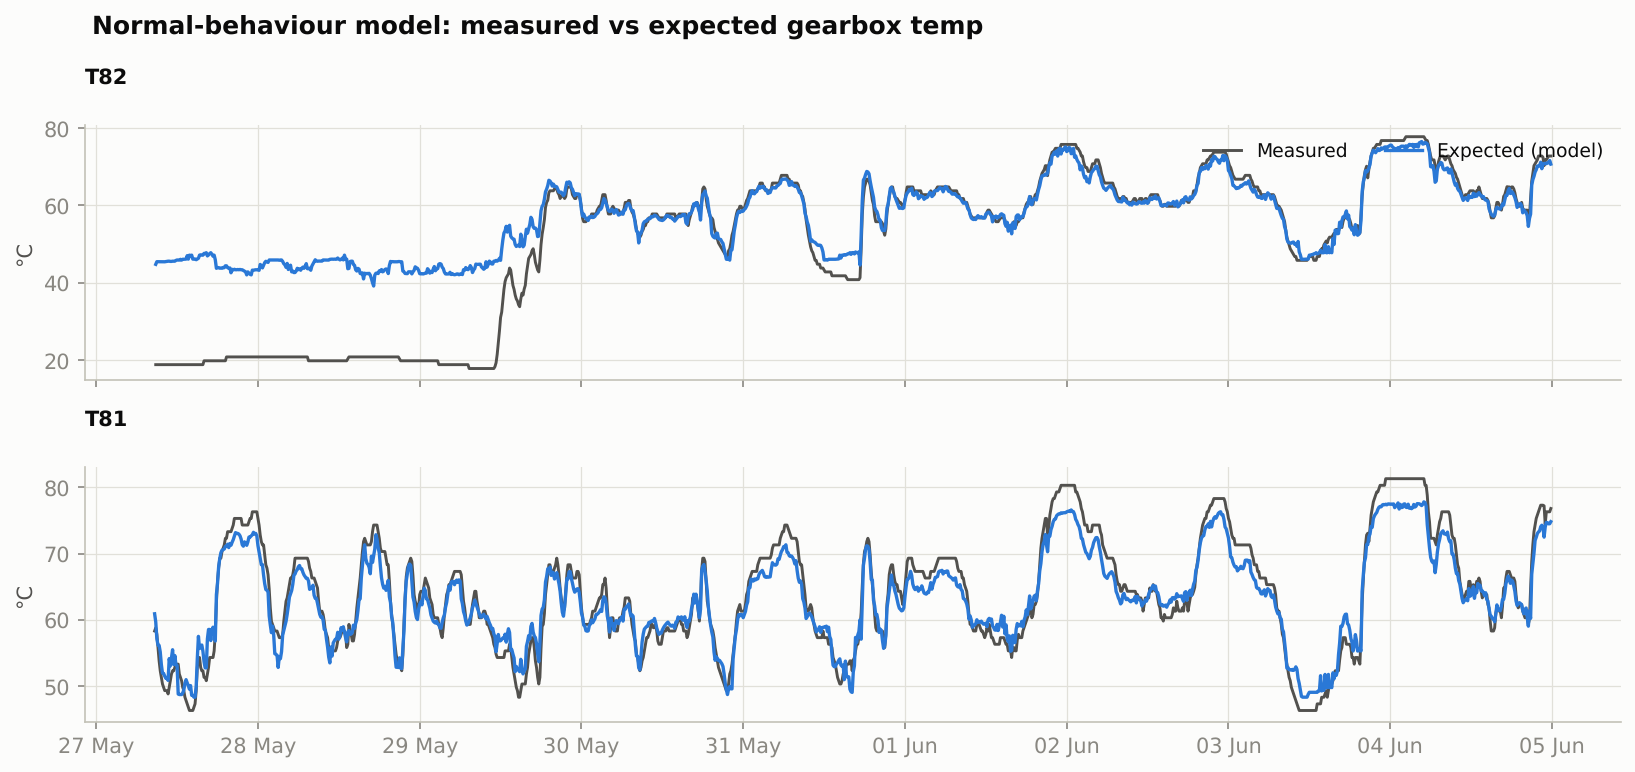

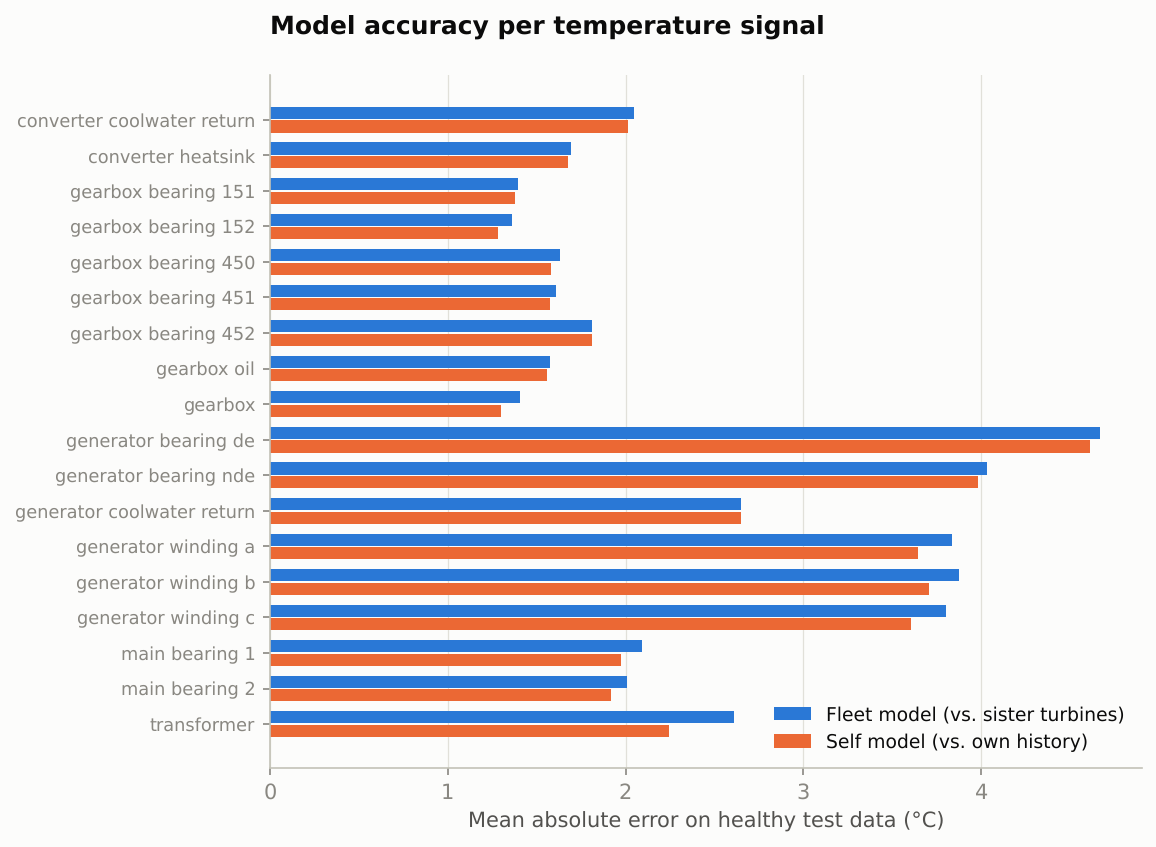

In [3]:
display(Image("../reports/figures/04_nbm_example.png", width=900))
display(Image("../reports/figures/05_nbm_accuracy.png", width=650))

The model explains most of the temperature variation from operating conditions alone (median error ≈ 2 °C,
vs. ≈ 4.4 °C for a plain average = "baseline"). What is left over, the residual, is what we monitor.

## 2. Fleet screening: static offsets in the training year

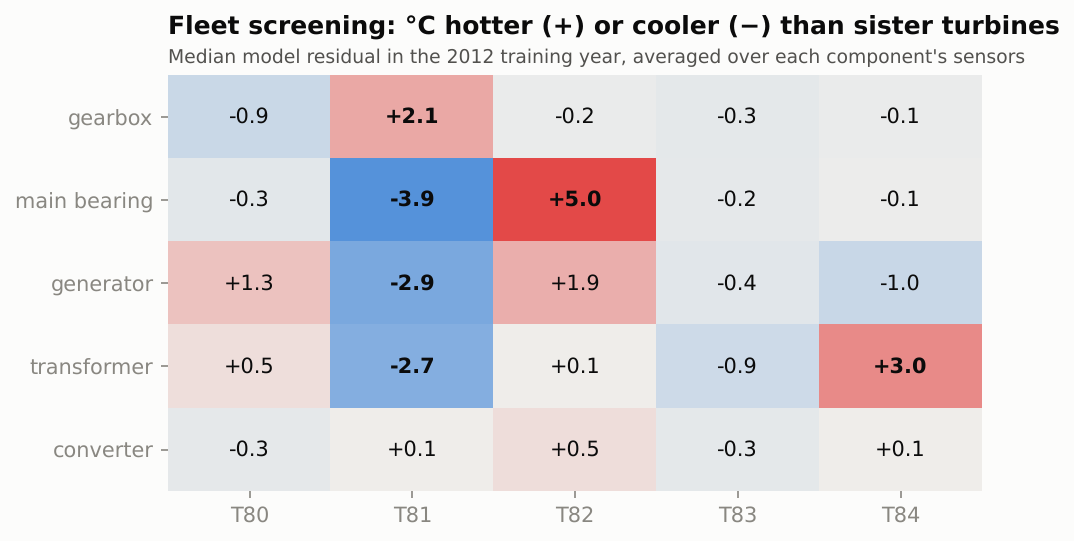

In [4]:
display(Image("../reports/figures/12_fleet_screening.png", width=700))

T81's gearbox runs ≈ 2 °C hotter than the model expects from its sister turbines (up to +7 °C on single bearings),
already in 2012. Other large offsets (T82 main bearing +5 °C, T84 transformer +3 °C) are candidates for an inspection or
a sensor check. Screening answers "which turbine is different?"; monitoring (next) answers "which turbine is *changing*?".

## 3. Health score and alarms: the T81 gearbox

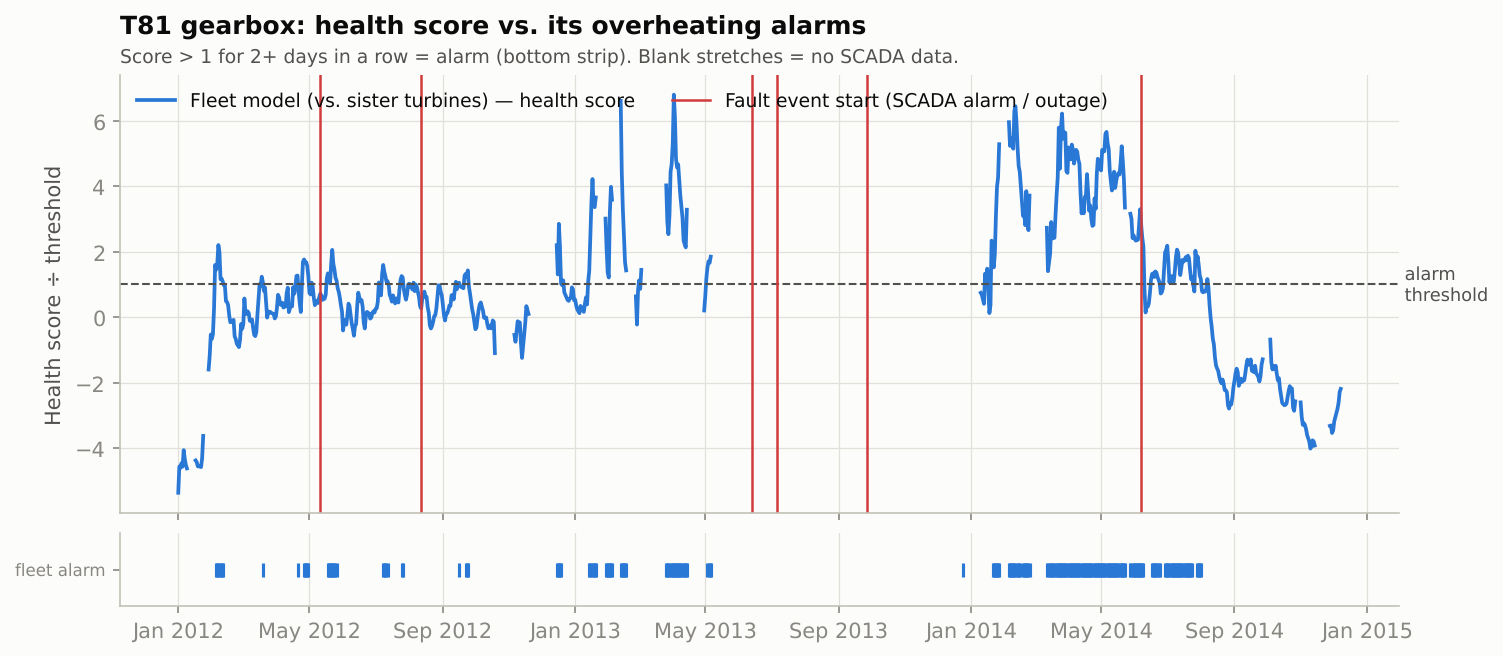

In [5]:
display(Image("../reports/figures/06_health_t81_gearbox.png", width=950))

* T81's gearbox gets **worse relative to its sister turbines** from late 2012: the score is far above the threshold
  through spring 2014, weeks before the June 2014 overheating season starts (30-day warning).
* After August 2014 the score drops below zero and stays there. The gearbox now runs *cooler* than in 2012,
  consistent with a repair or oil/cooler service (not recorded in the public data).
* Note: all five gearboxes drifted warmer together in 2013–14. Without common-mode rejection every turbine would alarm.

## 4. T84 before its 107-day outage

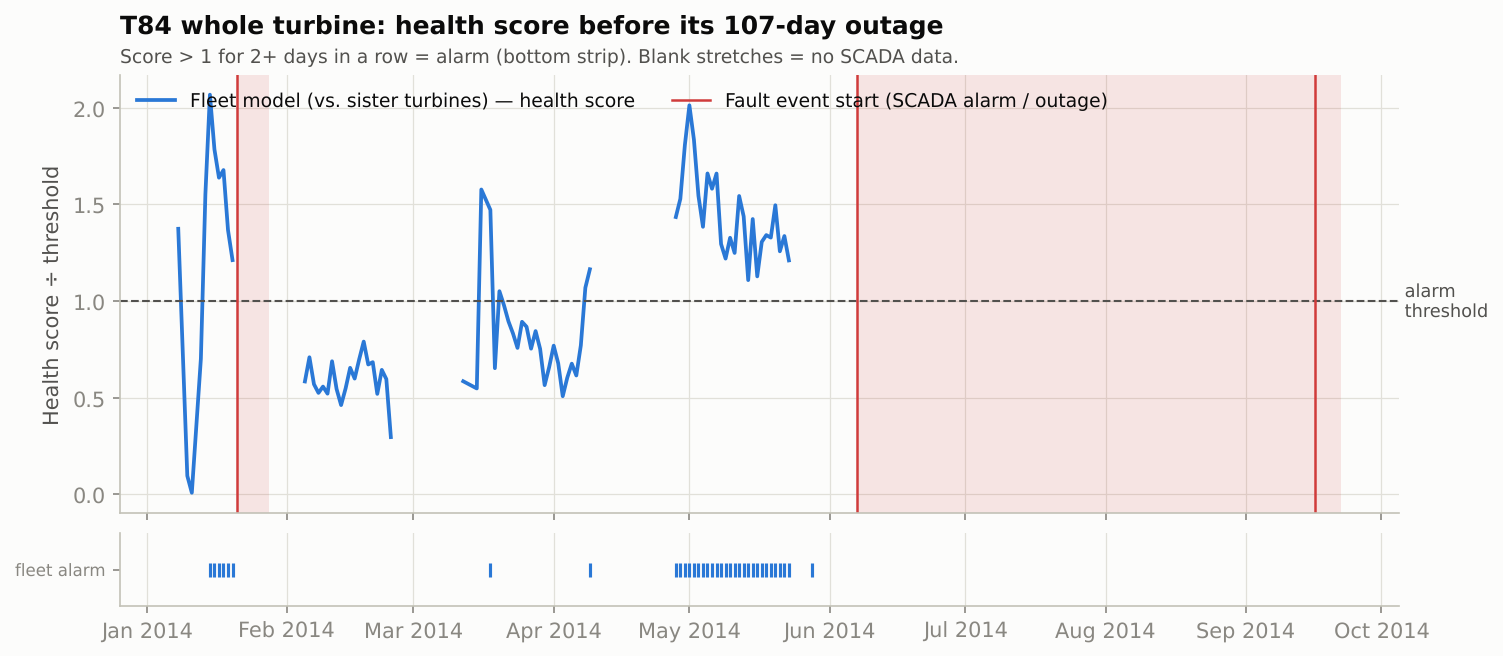

In [6]:
display(Image("../reports/figures/07_health_t84_outage.png", width=950))

T84's whole-turbine score crossed the threshold from early May 2014, a month before the converter/pitch failure that
kept it down for 107 days. The days right before the outage, when the logger scrambled its channels, are masked and
don't contribute.

## 5. Evaluation on the test period (2013–2014)

In [7]:
metrics = json.load(open("../reports/metrics_fuhrlander.json"))
rows = []
for m, s in metrics.items():
    t, th = s["turbine (any component) vs major outages"], s["all thermal-alarm events"]
    rows.append({"mode": m, "outages caught": f"{t['events_caught']}/{t['events_scorable']}",
                 "lead (outage, median d)": t["median_lead_days"],
                 "turbine-specific temp alarms": f"{s['turbine-specific thermal alarms']['events_caught']}/{s['turbine-specific thermal alarms']['events_scorable']}",
                 "fleet-wide temp alarms": f"{s['fleet-wide thermal alarms']['events_caught']}/{s['fleet-wide thermal alarms']['events_scorable']}",
                 "false alarms / turbine-yr": t["false_alarms_per_turbine_year"]})
pd.DataFrame(rows).set_index("mode")

,outages caught,"lead (outage, median d)",turbine-specific temp alarms,fleet-wide temp alarms,false alarms / turbine-yr
mode,,,,,
fleet,3/3,9.0,4/8,3/7,6.87
self,2/3,25.0,4/8,3/7,9.17
baseline,3/3,14.0,4/8,3/7,9.62


In [8]:
tbl = pd.read_parquet("../outputs/fuhrlander/events_scored_fleet.parquet")
tbl[tbl.scorable][["asset", "component", "kind", "start", "fleet_wide", "caught", "lead_days", "description"]]

,asset,component,kind,start,fleet_wide,caught,lead_days,description
0,80,gearbox,thermal_alarm,2014-06-09 17:06:32,True,True,30.0,"2 alarms (1 trips): MGB TempBear150 > SH, MGB Temp ErrTi..."
1,80,gearbox,thermal_alarm,2014-08-11 00:29:01,True,True,14.0,"4 alarms (2 trips): MGB TempBear150 > SH, MGB Temp ErrTi..."
5,81,gearbox,thermal_alarm,2014-06-06 15:22:00,False,True,30.0,"83 alarms (45 trips): MGB Temp ErrTimeLimit, MGB TempBea..."
8,82,gearbox,thermal_alarm,2014-07-17 16:48:00,False,False,NaN,"2 alarms (1 trips): MGB TempBear150 > SH, MGB Temp ErrTi..."
9,82,gearbox,thermal_alarm,2014-08-11 00:52:00,True,False,NaN,"4 alarms (2 trips): MGB TempBear150 > SH, MGB Temp ErrTi..."
11,83,gearbox,thermal_alarm,2014-06-09 16:38:00,True,False,NaN,"3 alarms (2 trips): MGB Temp ErrTimeLimit, MGB TempBear1..."
14,81,main_bearing,thermal_alarm,2014-11-19 11:35:00,False,False,NaN,"2 alarms (1 trips): M.bear. Temp 1 > SHH, M.bear. Temp 1..."
15,81,main_bearing,thermal_alarm,2014-12-04 12:11:00,True,False,NaN,"4 alarms (2 trips): M.bear. Temp 1 > SHH, M.bear. Temp 1..."
16,82,main_bearing,thermal_alarm,2014-12-04 15:44:00,True,False,NaN,"2 alarms (1 trips): M.bear. Temp 1 > SHH, M.bear. Temp 1..."
18,83,main_bearing,thermal_alarm,2014-12-05 09:41:00,True,True,29.0,"2 alarms (1 trips): M.bear. Temp 1 > SHH, M.bear. Temp 1..."


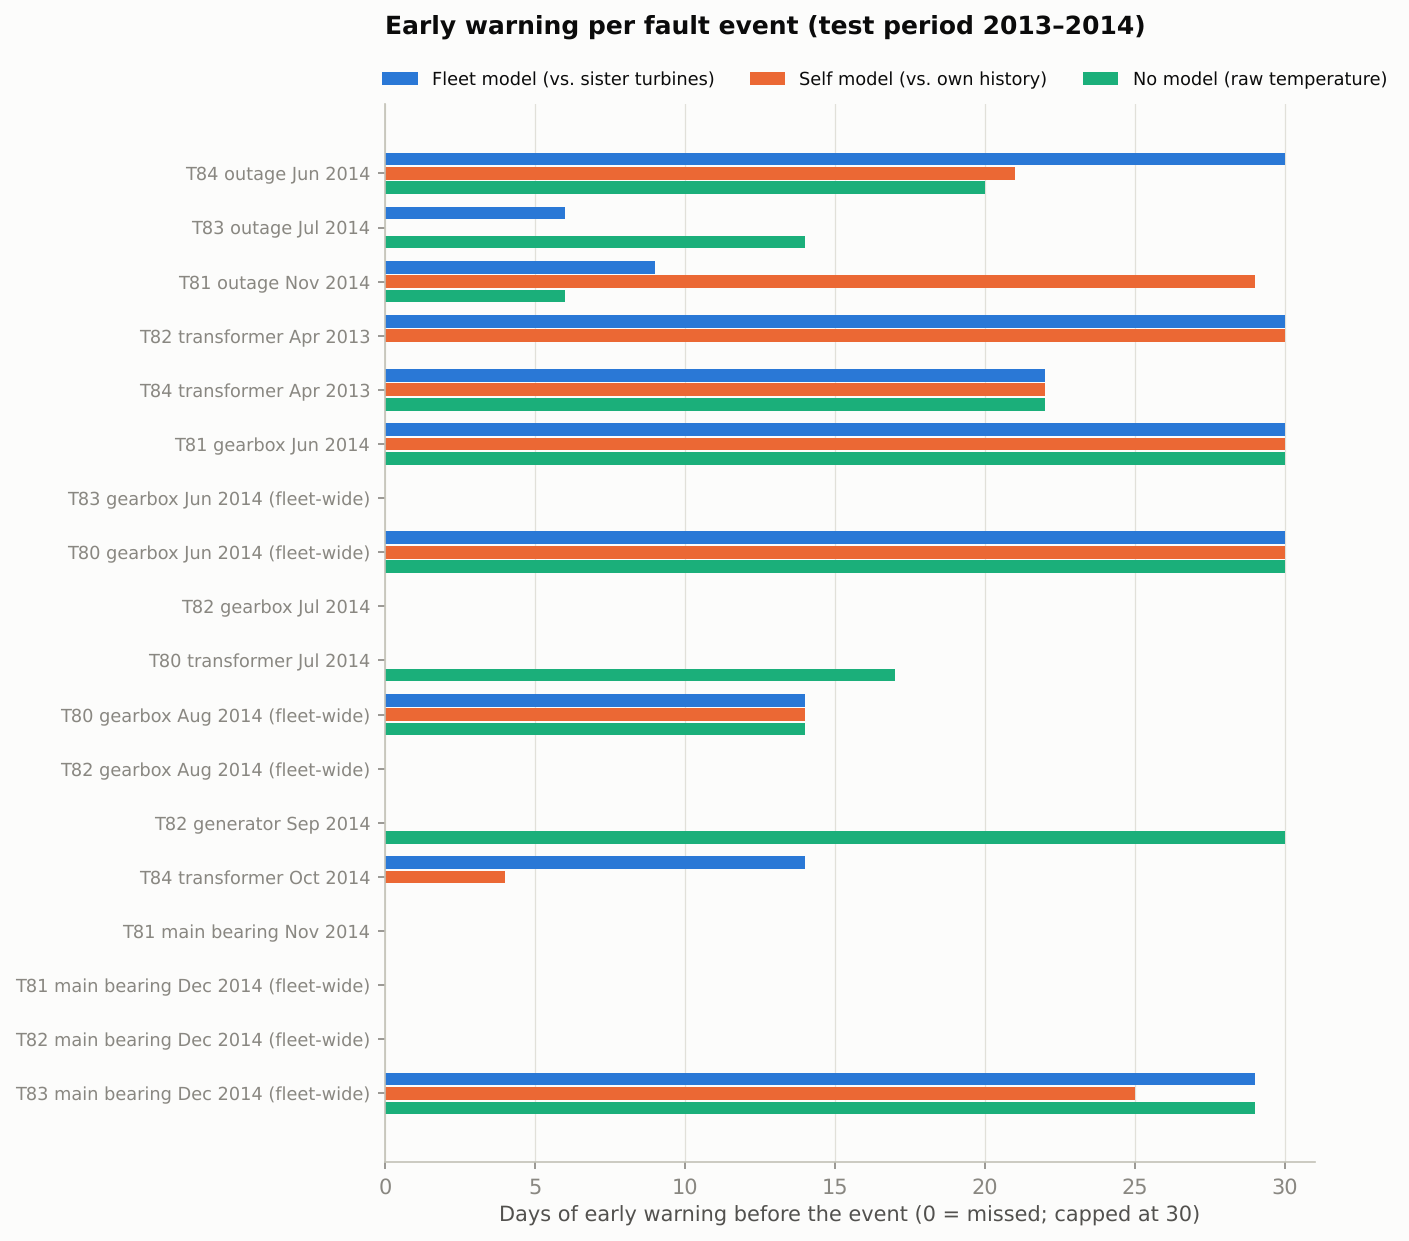

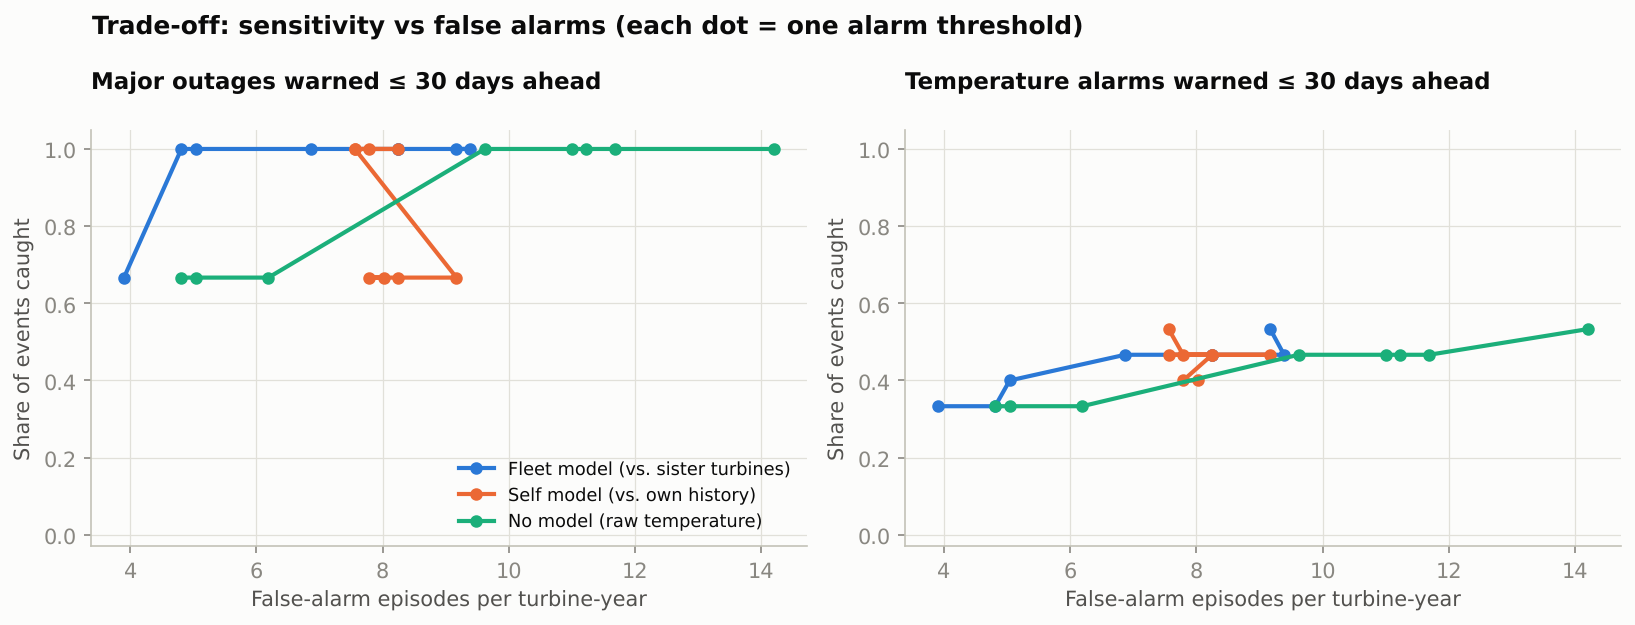

In [9]:
display(Image("../reports/figures/08_lead_times.png", width=750))
display(Image("../reports/figures/09_operating_curve.png", width=950))

**Reading the trade-off:** with ~18 scorable events the catch rates of the three approaches are close, so the fair comparison
is *at equal false-alarm rate*. There the fleet model is best for major outages: 3/3 warned at ≈ 5 false-alarm episodes per
turbine-year, where the self model needs ≈ 7.6 and raw temperature ≈ 9.6. False alarms are counted over 5 components;
an operator would typically review alarms weekly, so 5/turbine-year ≈ one check per turbine every ~10 weeks.

## 6. Failure prediction: fault event in the next 14 days

# Failure prediction (fleet health scores)

Target: thermal alarm or major outage starting within the next 14 days (turbine-day level). Train 2012-01-01–2013-01-01, test until 2015-01-01.

| features | model | roc_auc | pr_auc | base_rate | recall_at_10pct_budget | precision_at_10pct_budget | n_train_pos | n_test_pos | n_test |
|---|---|---|---|---|---|---|---|---|---|
| season | logistic | 0.611 | 0.249 | 0.155 | 0.187 | 0.346 | 269 | 235 | 1519 |
| season | lightgbm | 0.611 | 0.254 | 0.155 | 0.157 | 0.289 | 269 | 235 | 1519 |
| health | logistic | 0.528 | 0.197 | 0.155 | 0.196 | 0.207 | 269 | 235 | 1519 |
| health | lightgbm | 0.535 | 0.158 | 0.155 | 0.043 | 0.102 | 269 | 235 | 1519 |
| combined | logistic | 0.676 | 0.258 | 0.155 | 0.285 | 0.289 | 269 | 235 | 1519 |
| combined | lightgbm | 0.667 | 0.218 | 0.155 | 0.051 | 0.255 | 269 | 235 | 1519 |


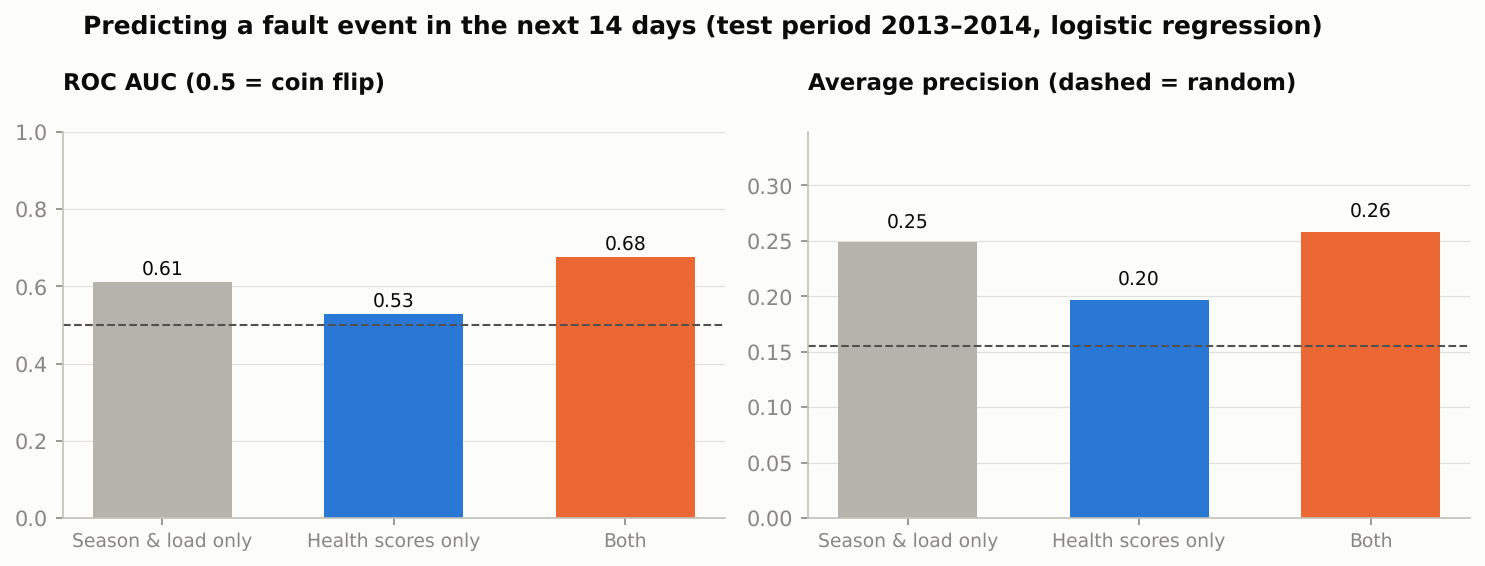

In [10]:
display(Markdown(open("../reports/prediction_fuhrlander.md").read()))
display(Image("../reports/figures/10_failure_prediction.png", width=850))

Honest result: predicting the exact 14-day window is hard with this little data. Season and load alone reach ROC AUC 0.61
(many alarms are just hot summers); adding the health scores lifts it to 0.68. Health scores alone are close to random
for *timing*, because they flag a degrading turbine for weeks to months, not a precise date. That's why alarms with a
30-day warning window are the more useful output for maintenance planning.